In [8]:
!pip install fastapi uvicorn python-multipart pillow numpy

In [9]:
from fastapi import FastAPI, UploadFile, File
from PIL import Image
import io
import numpy as np

app = FastAPI(title="VisionPort Traffic Detection")

@app.get("/")
def home():
    return {
        "message": "Welcome to VisionPort",
        "system": "Traffic Object Detection"
    }

@app.post("/predict")
async def predict(file: UploadFile = File(...)):

    image_bytes = await file.read()

    image = Image.open(
        io.BytesIO(image_bytes)
    ).convert("RGB")

    image = image.resize((640, 640))

    image_array = np.array(image)

    return {
        "message": "Image received successfully",
        "filename": file.filename,
        "image_size": image.size,
        "array_shape": image_array.shape
    }

print("VisionPort application created successfully!")

VisionPort application created successfully!


In [11]:
from fastapi.testclient import TestClient

client = TestClient(app)

response = client.get("/")

print("Status Code:", response.status_code)
print("Response:", response.json())

Status Code: 200
Response: {'message': 'Welcome to VisionPort', 'system': 'Traffic Object Detection'}


In [12]:
from PIL import Image
import io

# Create a sample image
image = Image.new("RGB", (640, 480), color="skyblue")

# Convert image into bytes
buffer = io.BytesIO()
image.save(buffer, format="JPEG")
buffer.seek(0)

# Upload image to FastAPI
response = client.post(
    "/predict",
    files={
        "file": (
            "traffic.jpg",
            buffer.getvalue(),
            "image/jpeg"
        )
    }
)

print("Status Code:", response.status_code)
print("Response:", response.json())

Status Code: 200
Response: {'message': 'Image received successfully', 'filename': 'traffic.jpg', 'image_size': [640, 640], 'array_shape': [640, 640, 3]}


In [13]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 11.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [14]:
from ultralytics import YOLO

# Load pretrained YOLO model
model = YOLO("yolov8n.pt")

print("YOLO AI Model Loaded Successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLO AI Model Loaded Successfully!


Saving Screenshot 2026-11-13 121154.png to Screenshot 2026-11-13 121154.png

image 1/1 /content/Screenshot 2026-11-13 121154.png: 320x640 1 person, 4 cars, 2 buss, 10.5ms
Speed: 66.8ms preprocess, 10.5ms inference, 22.8ms postprocess per image at shape (1, 3, 320, 640)


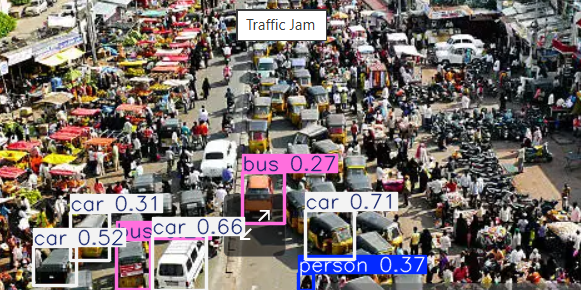

Object Detection Completed!


In [15]:
from google.colab import files

# Upload a traffic image
uploaded = files.upload()

# Get uploaded image name
image_path = list(uploaded.keys())[0]

# Detect objects using YOLO
results = model.predict(
    source=image_path,
    conf=0.25,
    show=False
)

# Display detected objects
results[0].show()

print("Object Detection Completed!")